
# Inteligencia Artificial – Universidad de Palermo

## Detección de insatisfacción de pasajeros – Invistico Airline

Dataset: [Airlines Customer Satisfaction – Kaggle](https://www.kaggle.com/datasets/sjleshrac/airlines-customer-satisfaction)

En Colab: Cambiar tipo de entorno de ejecución a R.

## 0. Instalación de paquetes
La descarga de `torch` puede demorar algunos minutos

In [1]:
pkgs <- c("rpart", "rpart.plot", "pROC", "ggplot2", "torch", "luz")
faltan <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

library(torch)
if (!torch_is_installed()) install_torch()

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘coro’, ‘safetensors’, ‘zeallot’




In [2]:
library(rpart)
library(rpart.plot)
library(pROC)
library(ggplot2)
library(torch)
library(luz)

set.seed(42)
torch_manual_seed(42)

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




## 1. Carga de datos
Se lee el CSV desde la carpeta local.

In [26]:
df <- read.csv("Invistico_Airline.csv", check.names = TRUE, stringsAsFactors = FALSE)

dim(df)
str(df)

[1] 129880     23

'data.frame':	129880 obs. of  23 variables:
 $ satisfaction                     : chr  "satisfied" "satisfied" "satisfied" "satisfied" ...
 $ Gender                           : chr  "Female" "Male" "Female" "Female" ...
 $ Customer.Type                    : chr  "Loyal Customer" "Loyal Customer" "Loyal Customer" "Loyal Customer" ...
 $ Age                              : int  65 47 15 60 70 30 66 10 56 22 ...
 $ Type.of.Travel                   : chr  "Personal Travel" "Personal Travel" "Personal Travel" "Personal Travel" ...
 $ Class                            : chr  "Eco" "Business" "Eco" "Eco" ...
 $ Flight.Distance                  : int  265 2464 2138 623 354 1894 227 1812 73 1556 ...
 $ Seat.comfort                     : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Departure.Arrival.time.convenient: int  0 0 0 0 0 0 0 0 0 0 ...
 $ Food.and.drink                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Gate.location                    : int  2 3 3 3 3 3 3 3 3 3 ...
 $ Inflight.wifi.service          

## 2. Análisis exploratorio

In [4]:
# Faltantes y duplicados
colSums(is.na(df))[colSums(is.na(df)) > 0]
cat("Filas duplicadas:", sum(duplicated(df)), "\n")

# Distribución de la variable objetivo
round(prop.table(table(df$satisfaction)) * 100, 1)

Arrival.Delay.in.Minutes 
                     393

Filas duplicadas: 0 



dissatisfied    satisfied 
        45.3         54.7 

grupo,insatisfechos,variable
<chr>,<dbl>,<chr>
Business,29.1,Class
Eco,60.6,Class
Eco Plus,57.3,Class
disloyal Customer,76.0,Customer.Type
Loyal Customer,38.4,Customer.Type
Business travel,41.6,Type.of.Travel
Personal Travel,53.4,Type.of.Travel
Female,34.9,Gender
Male,56.0,Gender


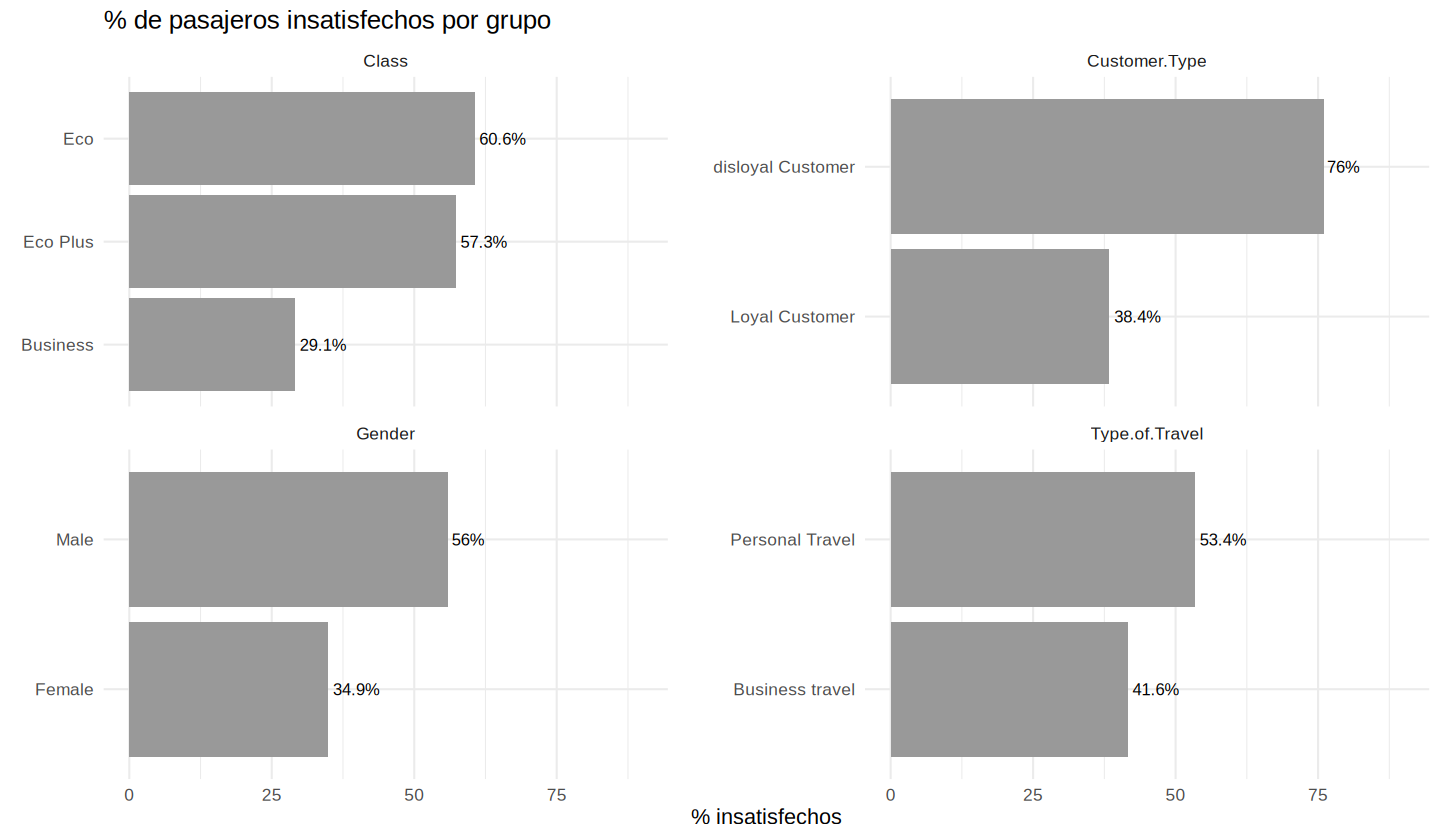

In [5]:
# % de insatisfechos por grupo
tasa <- function(var) {
  t <- tapply(df$satisfaction == "dissatisfied", df[[var]], mean)
  data.frame(grupo = names(t), insatisfechos = as.numeric(t), variable = var)
}
eda <- do.call(rbind, lapply(c("Class", "Customer.Type", "Type.of.Travel", "Gender"), tasa))
eda$insatisfechos <- round(eda$insatisfechos * 100, 1)
eda

ggplot(eda, aes(x = reorder(grupo, insatisfechos), y = insatisfechos)) +
  geom_col(fill = "grey60") +
  geom_text(aes(label = paste0(insatisfechos, "%")), hjust = -0.1, size = 3.5) +
  coord_flip() + facet_wrap(~ variable, scales = "free_y") +
  labs(title = "% de pasajeros insatisfechos por grupo", x = NULL, y = "% insatisfechos") +
  ylim(0, 90) + theme_minimal(base_size = 13)

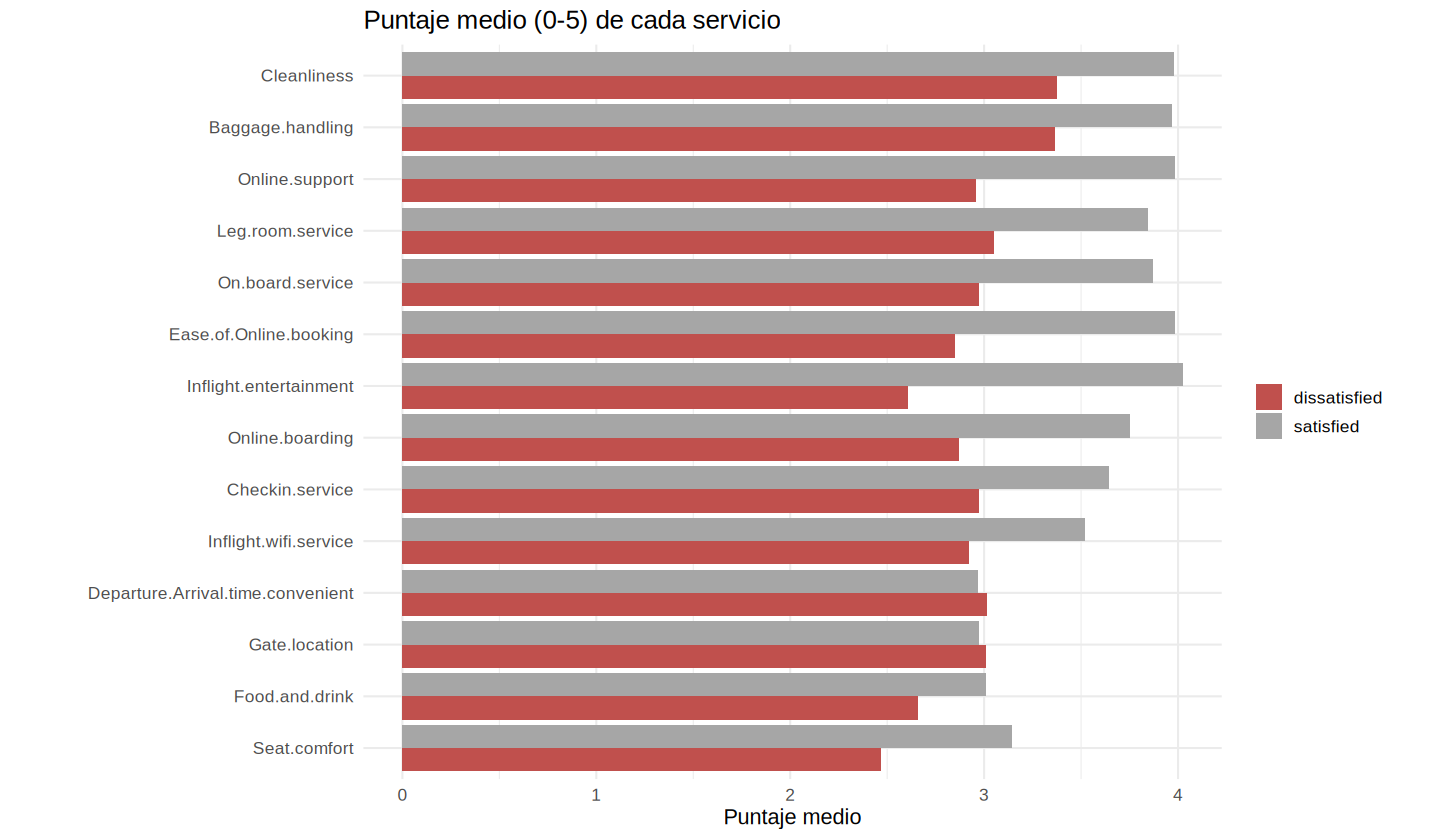

In [6]:
# Puntaje medio de cada servicio según satisfacción
servicios <- c("Seat.comfort", "Departure.Arrival.time.convenient", "Food.and.drink", "Gate.location",
               "Inflight.wifi.service", "Inflight.entertainment", "Online.support", "Ease.of.Online.booking",
               "On.board.service", "Leg.room.service", "Baggage.handling", "Checkin.service",
               "Cleanliness", "Online.boarding")
medias <- aggregate(df[, servicios], by = list(satisfaction = df$satisfaction), FUN = mean)
largo  <- reshape(medias, direction = "long", varying = servicios, v.names = "puntaje",
                  timevar = "servicio", times = servicios, idvar = "satisfaction")

ggplot(largo, aes(x = reorder(servicio, puntaje), y = puntaje, fill = satisfaction)) +
  geom_col(position = "dodge") + coord_flip() +
  scale_fill_manual(values = c(dissatisfied = "#c0504d", satisfied = "grey65")) +
  labs(title = "Puntaje medio (0-5) de cada servicio", x = NULL, y = "Puntaje medio", fill = NULL) +
  theme_minimal(base_size = 13)

## 3. Preprocesamiento
- Demora de llegada faltante (393 casos) → se completa con la demora de salida.
- Variables categóricas → factores.
- Variable objetivo: `insatisfecho` = **Si** / No (la clase positiva es la insatisfacción).

In [8]:
df$Arrival.Delay.in.Minutes[is.na(df$Arrival.Delay.in.Minutes)] <-
  df$Departure.Delay.in.Minutes[is.na(df$Arrival.Delay.in.Minutes)]

for (v in c("Gender", "Customer.Type", "Type.of.Travel", "Class")) df[[v]] <- factor(df[[v]])

df$insatisfecho <- factor(ifelse(df$satisfaction == "dissatisfied", "Si", "No"), levels = c("No", "Si"))
df$satisfaction <- NULL

sum(is.na(df))
table(df$insatisfecho)

[1] 0


   No    Si 
71087 58793 

## 4. Partición entrenamiento / prueba (70/30, estratificada)

In [9]:
set.seed(42)
idx_train <- unlist(lapply(split(seq_len(nrow(df)), df$insatisfecho),
                           function(i) sample(i, round(0.7 * length(i)))))
train <- df[idx_train, ]
test  <- df[-idx_train, ]

c(train = nrow(train), test = nrow(test))
round(prop.table(table(test$insatisfecho)), 3)

train  test 
90916 38964


   No    Si 
0.547 0.453 

In [10]:
# Función de métricas (clase positiva = insatisfecho "Si")
metricas <- function(real, prob, nombre, umbral = 0.5) {
  pred <- ifelse(prob >= umbral, "Si", "No")
  vp <- sum(pred == "Si" & real == "Si"); vn <- sum(pred == "No" & real == "No")
  fp <- sum(pred == "Si" & real == "No"); fn <- sum(pred == "No" & real == "Si")
  sens <- vp / (vp + fn); prec <- vp / (vp + fp)
  data.frame(modelo = nombre,
             exactitud = round((vp + vn) / length(real), 4),
             sensibilidad = round(sens, 4),
             especificidad = round(vn / (vn + fp), 4),
             precision = round(prec, 4),
             F1 = round(2 * prec * sens / (prec + sens), 4),
             AUC = round(as.numeric(auc(roc(real, prob, levels = c("No", "Si"), direction = "<", quiet = TRUE))), 4))
}
matriz <- function(real, prob, umbral = 0.5) {
  table(Real = real, Predicho = factor(ifelse(prob >= umbral, "Si", "No"), levels = c("No", "Si")))
}

## 5. Modelo 1 – Árbol de decisión
Se hace crecer un árbol grande (`cp` muy bajo) y se poda con el `cp` que minimiza el error de validación cruzada de 10 particiones.

cp óptimo: 0.0001104472 
Hojas del árbol óptimo: 211 


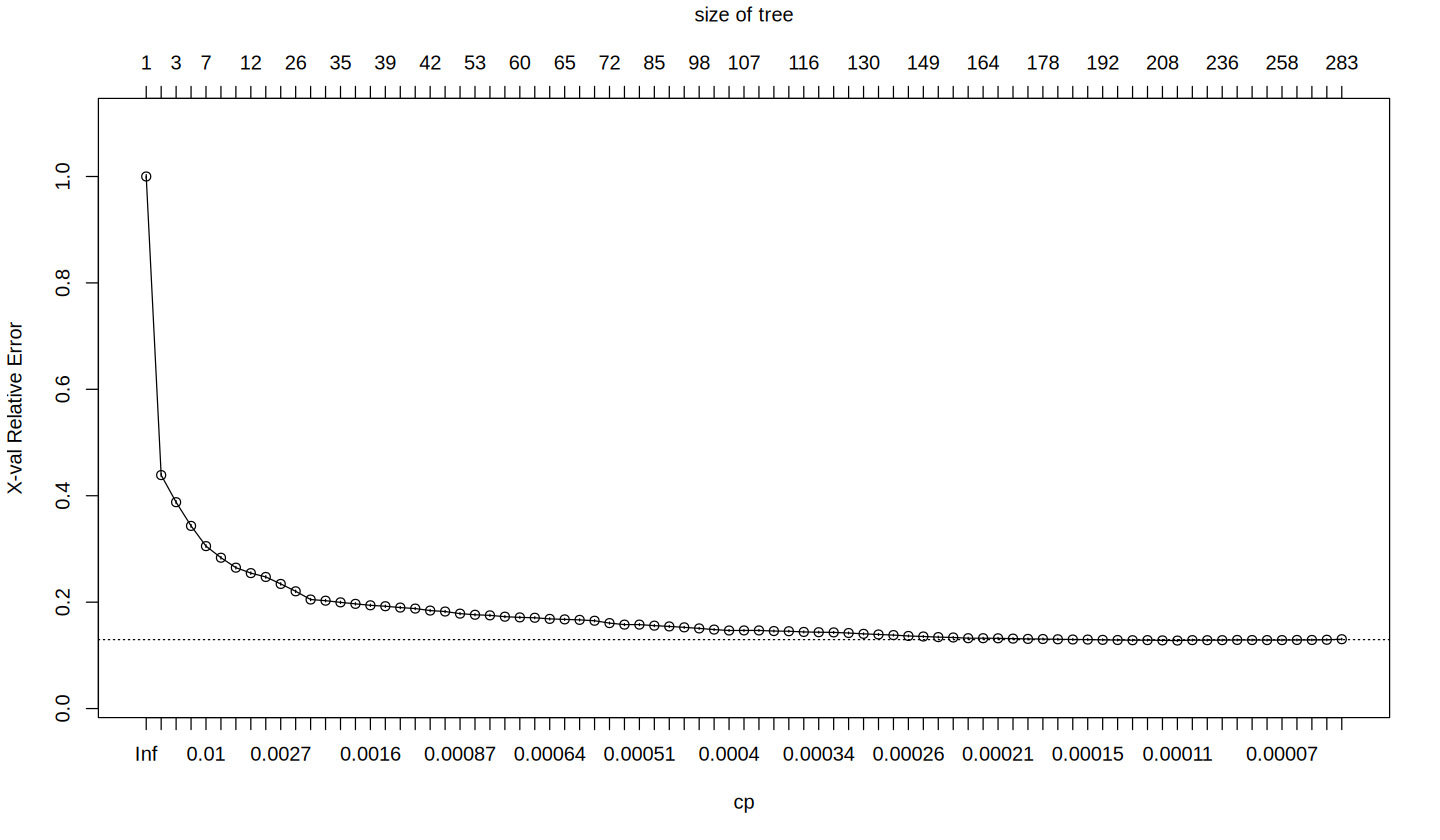

In [11]:
set.seed(42)
arbol_full <- rpart(insatisfecho ~ ., data = train, method = "class",
                    control = rpart.control(cp = 0.00005, minbucket = 20, xval = 10))

tabla_cp <- arbol_full$cptable
cp_opt   <- tabla_cp[which.min(tabla_cp[, "xerror"]), "CP"]
cat("cp óptimo:", cp_opt, "\n")

arbol_opt <- prune(arbol_full, cp = cp_opt)
cat("Hojas del árbol óptimo:", sum(arbol_opt$frame$var == "<leaf>"), "\n")

plotcp(arbol_full)

In [12]:
prob_opt <- predict(arbol_opt, test, type = "prob")[, "Si"]
matriz(test$insatisfecho, prob_opt)
res_opt <- metricas(test$insatisfecho, prob_opt, "Árbol óptimo")
res_opt

    Predicho
Real    No    Si
  No 20143  1183
  Si   979 16659

modelo,exactitud,sensibilidad,especificidad,precision,F1,AUC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Árbol óptimo,0.9445,0.9445,0.9445,0.9337,0.9391,0.9859


,variable,importancia
,<chr>,<dbl>
Inflight.entertainment,Inflight.entertainment,23.5
Seat.comfort,Seat.comfort,17.0
Online.support,Online.support,11.1
Ease.of.Online.booking,Ease.of.Online.booking,9.6
Food.and.drink,Food.and.drink,8.9
Online.boarding,Online.boarding,7.8
Customer.Type,Customer.Type,2.5
Type.of.Travel,Type.of.Travel,2.4
Departure.Arrival.time.convenient,Departure.Arrival.time.convenient,2.0


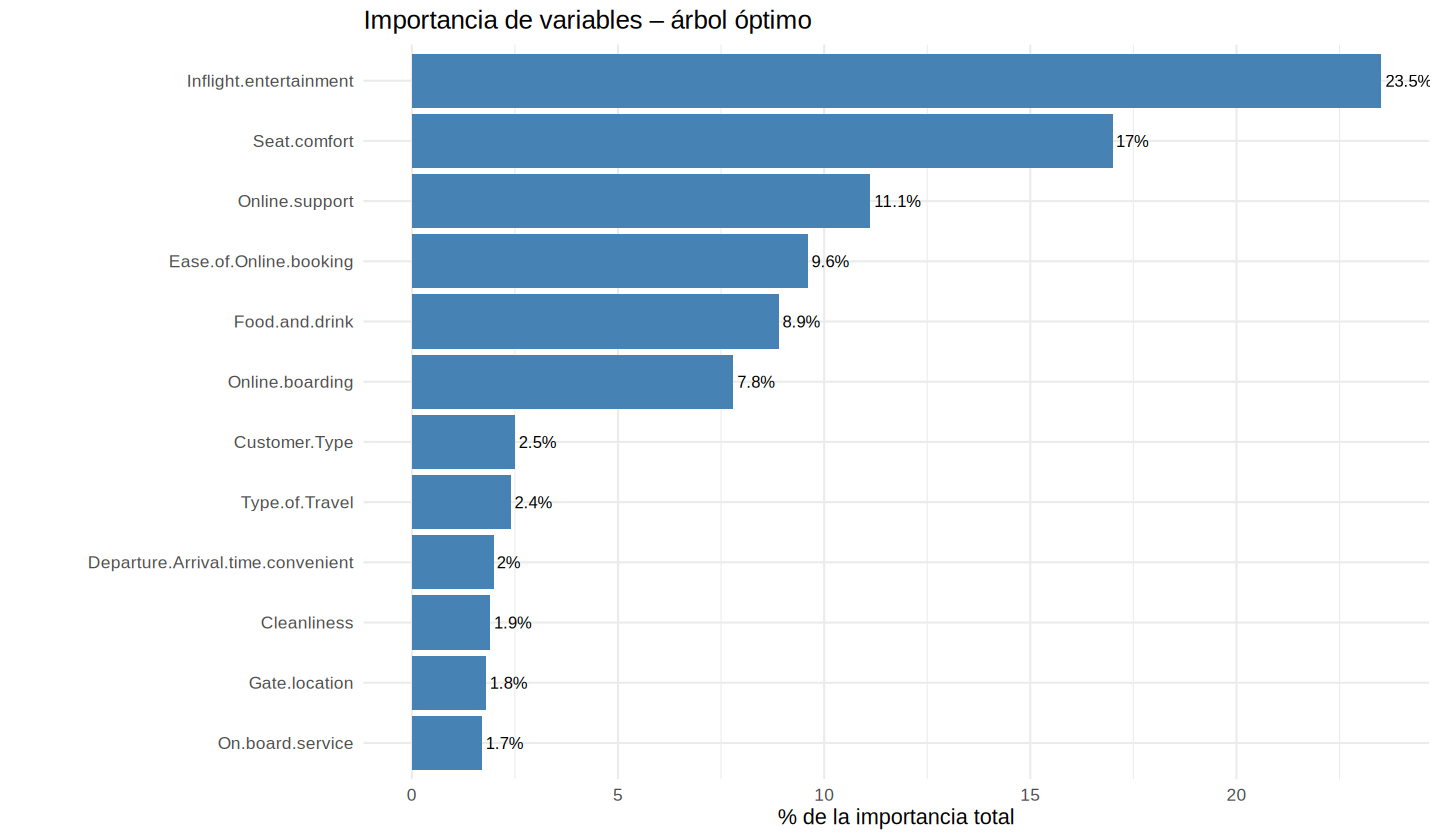

In [13]:
# Importancia de variables del árbol óptimo (% del total)
imp <- arbol_opt$variable.importance
imp <- data.frame(variable = names(imp), importancia = round(100 * imp / sum(imp), 1))
head(imp, 10)

ggplot(head(imp, 12), aes(x = reorder(variable, importancia), y = importancia)) +
  geom_col(fill = "steelblue") + coord_flip() +
  geom_text(aes(label = paste0(importancia, "%")), hjust = -0.1, size = 3.5) +
  labs(title = "Importancia de variables – árbol óptimo", x = NULL, y = "% de la importancia total") +
  theme_minimal(base_size = 13)

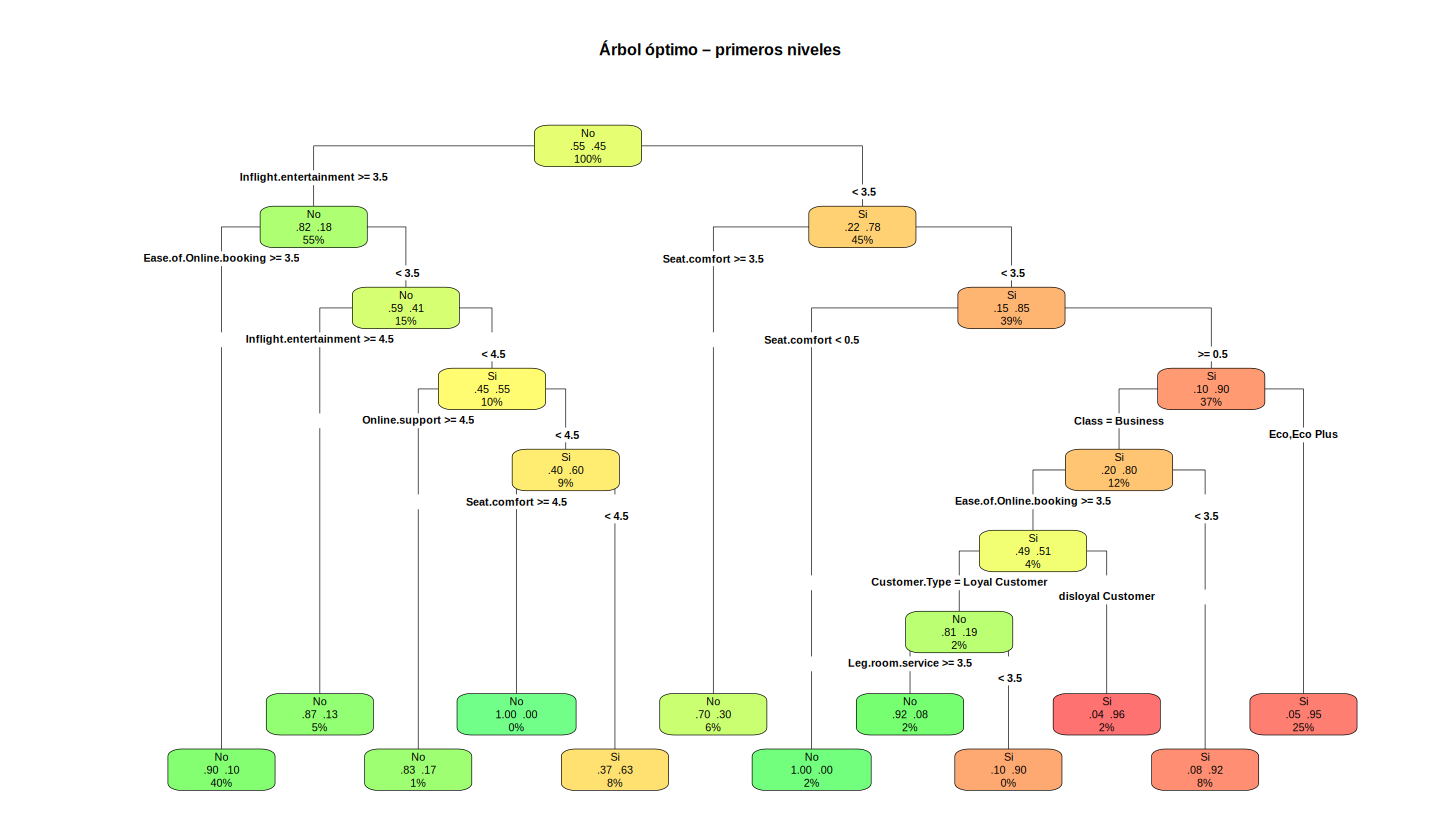

In [14]:
# El árbol óptimo tiene cientos de hojas: se grafican solo sus primeros niveles como referencia
rpart.plot(prune(arbol_opt, cp = 0.005), type = 4, extra = 104, roundint = FALSE,
           box.palette = "GnYlRd", main = "Árbol óptimo – primeros niveles")

## 5b. Modelo – Árbol de decisión más chico
Profundidad máxima 3 y hojas de al menos 500 pasajeros

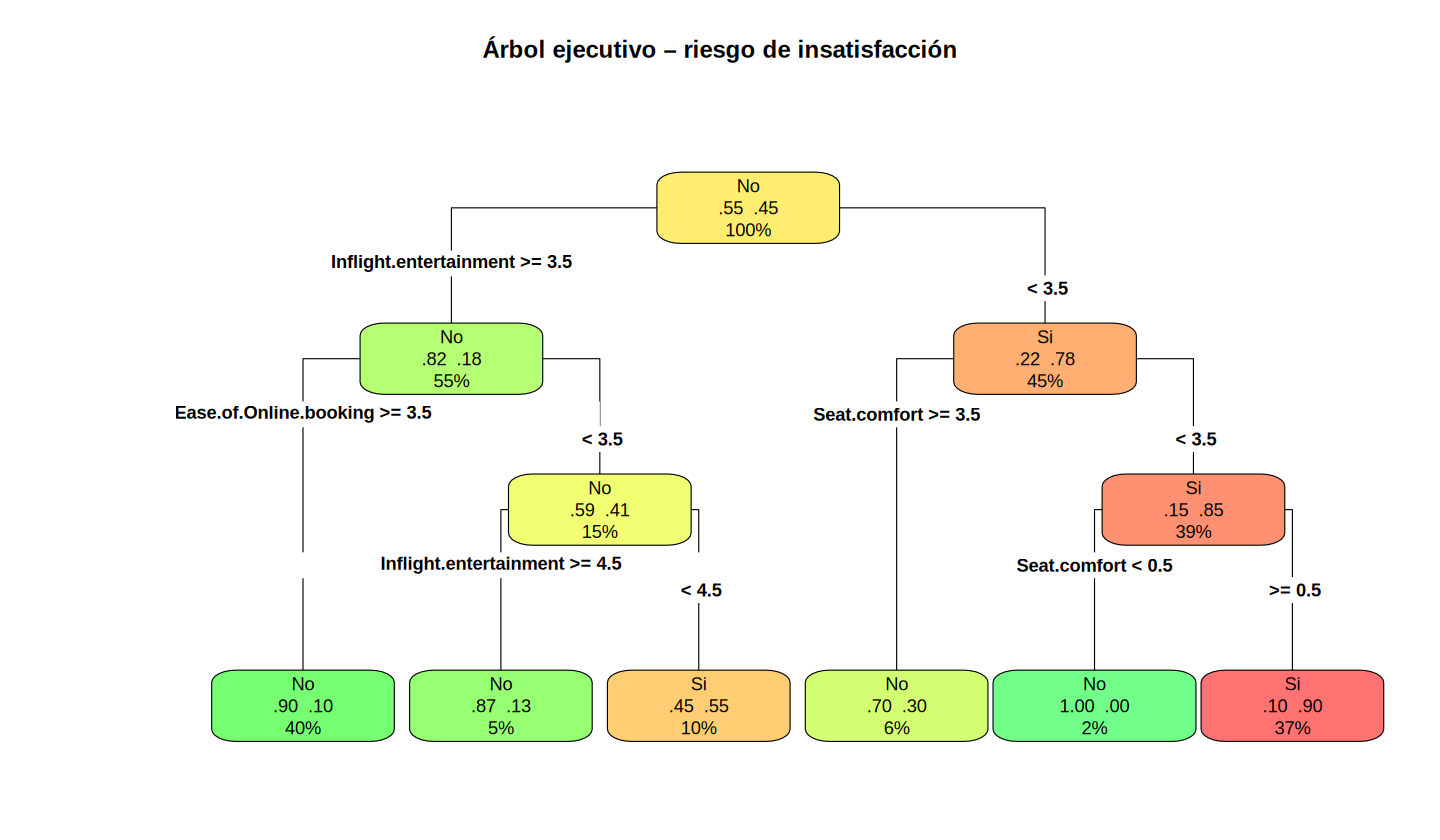

In [15]:
arbol_ejec <- rpart(insatisfecho ~ ., data = train, method = "class",
                    control = rpart.control(maxdepth = 3, cp = 0.001, minbucket = 500, xval = 0))

rpart.plot(arbol_ejec, type = 4, extra = 104, roundint = FALSE, box.palette = "GnYlRd",
           main = "Árbol ejecutivo – riesgo de insatisfacción")

In [16]:
# Reglas en texto: probabilidad de insatisfacción ("Si") y condiciones
rpart.rules(arbol_ejec, roundint = FALSE, cover = TRUE)

,insatisfecho,,,,,,,,,,,,,,,,,cover
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
14,0.00,when,Inflight.entertainment,<,3.5,,,,,,,&,Seat.comfort,<,0.5,,,2%
4,0.10,when,Inflight.entertainment,>=,,,3.5,&,Ease.of.Online.booking,>=,3.5,,,,,,,40%
10,0.13,when,Inflight.entertainment,>=,,,4.5,&,Ease.of.Online.booking,<,3.5,,,,,,,5%
6,0.30,when,Inflight.entertainment,<,3.5,,,,,,,&,Seat.comfort,>=,,,3.5,6%
11,0.55,when,Inflight.entertainment,is,3.5,to,4.5,&,Ease.of.Online.booking,<,3.5,,,,,,,10%
15,0.90,when,Inflight.entertainment,<,3.5,,,,,,,&,Seat.comfort,is,0.5,to,3.5,37%


In [17]:
prob_ejec <- predict(arbol_ejec, test, type = "prob")[, "Si"]
matriz(test$insatisfecho, prob_ejec)
res_ejec <- metricas(test$insatisfecho, prob_ejec, "Árbol ejecutivo (3 niveles)")
res_ejec

    Predicho
Real    No    Si
  No 18130  3196
  Si  2390 15248

modelo,exactitud,sensibilidad,especificidad,precision,F1,AUC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Árbol ejecutivo (3 niveles),0.8566,0.8645,0.8501,0.8267,0.8452,0.8982


## 6. Modelo 2 – Red neuronal chica con dropout (`torch` + `luz`)
- Entrada: variables numéricas estandarizadas + dummies de las categóricas.
- Arquitectura: 16 → 8 neuronas (ReLU) con **dropout 30%**, salida de 1 neurona (logit).
- Pérdida: entropía cruzada binaria · Optimizador: Adam · *Early stopping* sobre un 10% de validación.

In [18]:
# Matriz de diseño
X_tr <- model.matrix(insatisfecho ~ ., data = train)[, -1]
X_te <- model.matrix(insatisfecho ~ ., data = test)[, -1]

# Estandarización con media y desvío del entrenamiento
medias_tr <- colMeans(X_tr)
desvios_tr <- apply(X_tr, 2, sd)
X_tr <- sweep(sweep(X_tr, 2, medias_tr), 2, desvios_tr, "/")
X_te <- sweep(sweep(X_te, 2, medias_tr), 2, desvios_tr, "/")

y_tr <- as.numeric(train$insatisfecho == "Si")
y_te <- as.numeric(test$insatisfecho == "Si")

x_tr_t <- torch_tensor(X_tr, dtype = torch_float())
y_tr_t <- torch_tensor(matrix(y_tr, ncol = 1), dtype = torch_float())
x_te_t <- torch_tensor(X_te, dtype = torch_float())

dim(X_tr)

[1] 90916    23

In [19]:
red_chica <- nn_module(
  "RedChica",
  initialize = function(d_in, p_drop = 0.3) {
    self$capa1  <- nn_linear(d_in, 16)
    self$capa2  <- nn_linear(16, 8)
    self$salida <- nn_linear(8, 1)
    self$drop   <- nn_dropout(p = p_drop)
  },
  forward = function(x) {
    x %>%
      self$capa1() %>% nnf_relu() %>% self$drop() %>%
      self$capa2() %>% nnf_relu() %>% self$drop() %>%
      self$salida()
  }
)

torch_manual_seed(42)
ajuste_red <- red_chica %>%
  setup(
    loss = nn_bce_with_logits_loss(),
    optimizer = optim_adam,
    metrics = list(luz_metric_binary_accuracy_with_logits(),
                   luz_metric_binary_auroc(from_logits = TRUE))
  ) %>%
  set_hparams(d_in = ncol(X_tr), p_drop = 0.3) %>%
  set_opt_hparams(lr = 0.001) %>%
  fit(
    data = list(x_tr_t, y_tr_t),
    valid_data = 0.1,
    epochs = 40,
    dataloader_options = list(batch_size = 256, shuffle = TRUE),
    callbacks = list(luz_callback_early_stopping(monitor = "valid_loss", patience = 4)),
    verbose = TRUE
  )

Epoch 1/40
Train metrics: Loss: 0.5045 - Acc: 0.7412 - AUC: 0.8507
Valid metrics: Loss: 0.3309 - Acc: 0.8643 - AUC: 0.9321
Epoch 2/40
Train metrics: Loss: 0.3469 - Acc: 0.8632 - AUC: 0.9255
Valid metrics: Loss: 0.2718 - Acc: 0.8896 - AUC: 0.9554
Epoch 3/40
Train metrics: Loss: 0.3139 - Acc: 0.8796 - AUC: 0.9384
Valid metrics: Loss: 0.2485 - Acc: 0.8994 - AUC: 0.9629
Epoch 4/40
Train metrics: Loss: 0.2997 - Acc: 0.8855 - AUC: 0.9435
Valid metrics: Loss: 0.2371 - Acc: 0.9052 - AUC: 0.9662
Epoch 5/40
Train metrics: Loss: 0.2883 - Acc: 0.8894 - AUC: 0.9476
Valid metrics: Loss: 0.2284 - Acc: 0.9084 - AUC: 0.9684
Epoch 6/40
Train metrics: Loss: 0.2799 - Acc: 0.8934 - AUC: 0.9506
Valid metrics: Loss: 0.223 - Acc: 0.9096 - AUC: 0.9698
Epoch 7/40
Train metrics: Loss: 0.2733 - Acc: 0.8958 - AUC: 0.9529
Valid metrics: Loss: 0.2173 - Acc: 0.9123 - AUC: 0.9715
Epoch 8/40
Train metrics: Loss: 0.2687 - Acc: 0.8962 - AUC: 0.9544
Valid metrics: Loss: 0.2127 - Acc: 0.9133 - AUC: 0.9725
Epoch 9/40
Train 

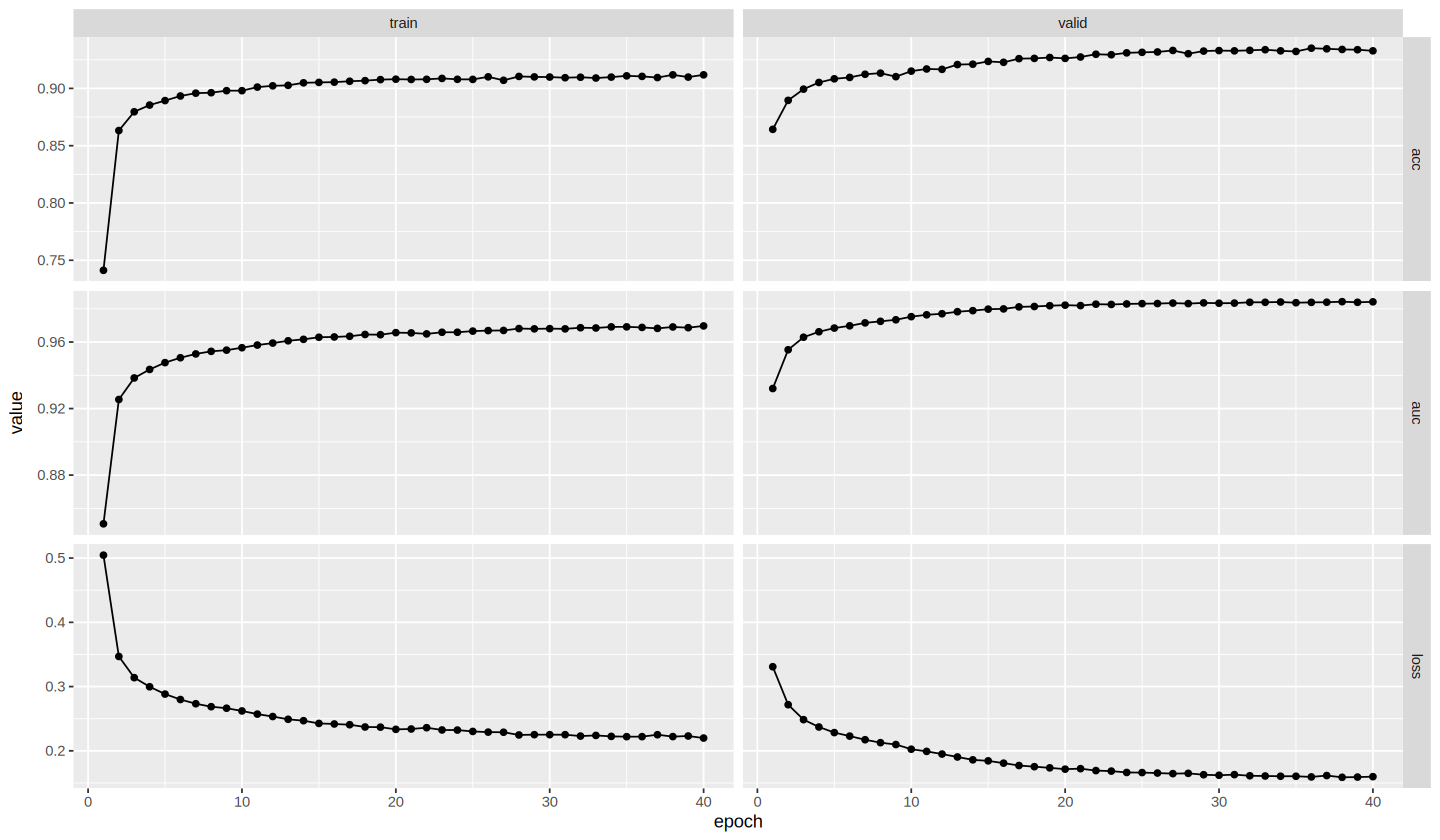

In [20]:
# Curvas de entrenamiento y validación
plot(ajuste_red)

In [21]:
ajuste_red$model$eval()
logits   <- predict(ajuste_red, list(x_te_t))
prob_red <- as.numeric(torch_sigmoid(logits)$cpu())

matriz(test$insatisfecho, prob_red)
res_red <- metricas(test$insatisfecho, prob_red, "Red neuronal 16-8 + dropout")
res_red

    Predicho
Real    No    Si
  No 20188  1138
  Si  1397 16241

modelo,exactitud,sensibilidad,especificidad,precision,F1,AUC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Red neuronal 16-8 + dropout,0.9349,0.9208,0.9466,0.9345,0.9276,0.9859


## 7. Comparación de modelos

In [23]:
comparacion <- rbind(res_ejec, res_opt, res_red)
comparacion

modelo,exactitud,sensibilidad,especificidad,precision,F1,AUC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Árbol ejecutivo (3 niveles),0.8566,0.8645,0.8501,0.8267,0.8452,0.8982
Árbol óptimo,0.9445,0.9445,0.9445,0.9337,0.9391,0.9859
Red neuronal 16-8 + dropout,0.9349,0.9208,0.9466,0.9345,0.9276,0.9859


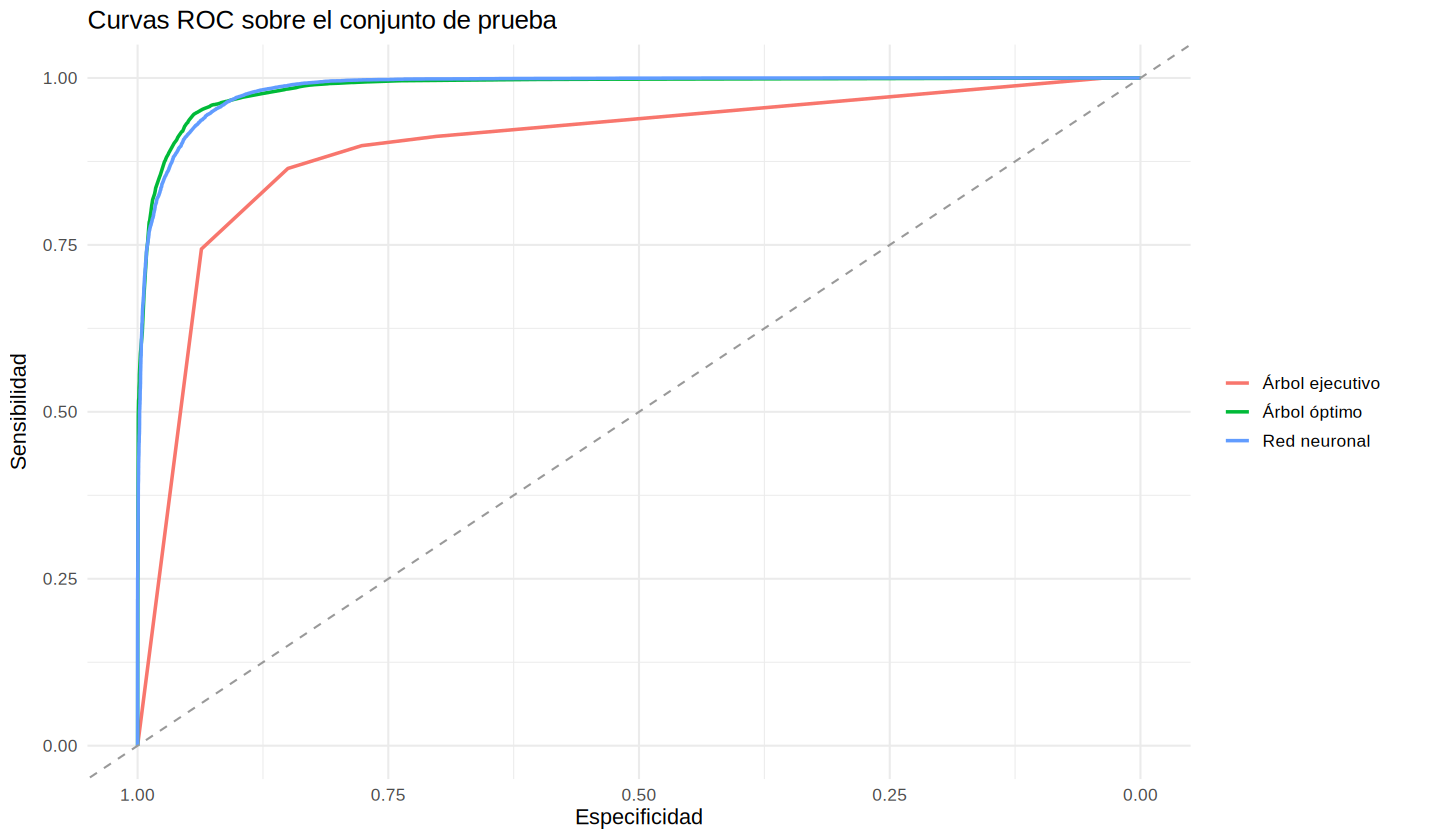

In [24]:
roc_ejec <- roc(test$insatisfecho, prob_ejec, levels = c("No", "Si"), direction = "<", quiet = TRUE)
roc_opt  <- roc(test$insatisfecho, prob_opt,  levels = c("No", "Si"), direction = "<", quiet = TRUE)
roc_red  <- roc(test$insatisfecho, prob_red,  levels = c("No", "Si"), direction = "<", quiet = TRUE)

ggroc(list(`Árbol ejecutivo` = roc_ejec, `Árbol óptimo` = roc_opt, `Red neuronal` = roc_red), linewidth = 1) +
  geom_abline(slope = 1, intercept = 1, linetype = "dashed", colour = "grey60") +
  labs(title = "Curvas ROC sobre el conjunto de prueba", colour = NULL,
       x = "Especificidad", y = "Sensibilidad") +
  theme_minimal(base_size = 13)

In [25]:
# Variables más importantes en ambos enfoques
merge(head(imp, 10), head(imp_red, 10), by = "variable", all = TRUE)

variable,importancia,caida_AUC
<chr>,<dbl>,<dbl>
Baggage.handling,NA,0.0112
Cleanliness,1.9,NA
Customer.Type,2.5,NA
Customer.TypeLoyal Customer,NA,0.0570
Departure.Arrival.time.convenient,2.0,0.0029
Ease.of.Online.booking,9.6,0.0046
Food.and.drink,8.9,NA
Gate.location,NA,0.0031
GenderMale,NA,0.0308
